# Model fitting with numpy and scipy
`author` Julien Morin <julien.morin@umontpellier.fr>

`date` 20 Oct 2021

References: __[Scipy Cookbook #Fitting Data](https://scipy-cookbook.readthedocs.io/items/FittingData.html)__ ; *Numerical Recipes in C* §15

In [1]:
# import and settings
import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize as opt

In [2]:
# Generate synthetic measurements
Nmod = 100
a = 2.
b = 5.
sig0 = 4.
x = np.linspace(-10,10,200)
noise = []
for i in range(Nmod):
    noise.append(np.random.normal(0., sig0, x.shape))
ymod = a * x + b
ymeas = ymod + noise
print(len(ymeas), ymeas[0].shape)
sig = sig0 * np.ones_like(x)
# check noise properties
print(len(noise), noise[0].shape)
print("mean(noise[0]) = %.4f ; std(noise[0]) = %.4f" % (np.mean(noise[0]), np.std(noise[0])))
print("mean(noise) = %.4f ; std(noise) = %.4f" % (np.mean(noise), np.std(noise)))

100 (200,)
100 (200,)
mean(noise[0]) = 0.3367 ; std(noise[0]) = 3.6587
mean(noise) = -0.0566 ; std(noise) = 3.9497


In [3]:
# define the fit function and the error function
fitfunc = lambda x, a, b: a*x + b  # Target function

In [4]:
# define initial guess for the fit parameters anc compute corresponding model
p0 = [1., 0.]
y0 = fitfunc(x, *p0)
# perform fit
popt = []
pcov = []
for ym in ymeas:
    po, pc= opt.curve_fit(fitfunc, x, ym, sigma=sig, p0=p0, absolute_sigma=True, method='lm')
    popt.append(po)
    pcov.append(pc)
# compute best-fit model
yopt = []
for po in popt: 
    yopt.append(fitfunc(x, *po))

(-15.0, 15.0)

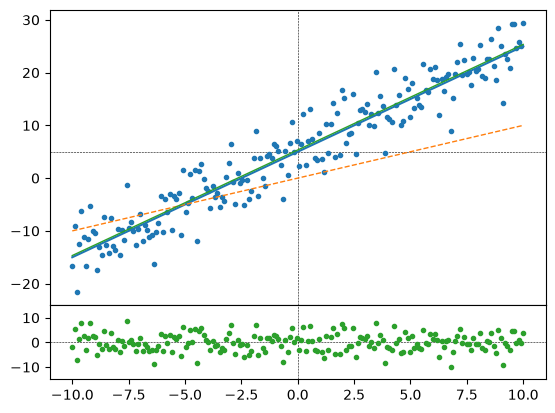

In [5]:
# plot data and model
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, gridspec_kw={'height_ratios': [4, 1]})
fig.subplots_adjust(hspace=0)
# main plot
ax1.axvline(0., ls='--', c='k', lw=0.4)
ax1.axhline(b, ls='--', c='k', lw=0.4)
ax1.plot(x, ymeas[0], marker='o', ms=3., color='tab:blue', ls='')
ax1.plot(x,ymod, c='tab:blue')
ax1.plot(x,y0, c='tab:orange', ls='--', lw=1.)
ax1.plot(x,yopt[0], c='tab:green', ls='-', lw=1.)
# residual 'O-C'
ax2.axhline(0., ls='--', c='k', lw=0.4)
ax2.axvline(0., ls='--', c='k', lw=0.4)
ax2.plot(x, ymeas[0]-yopt[0], 'o', c='tab:green', ms=3.)
ax2.set_ylim(-15,15)
#plt.setp(ax1.get_xticklabels(), visible=False)

In [6]:
# reduced chi square
chisqr = lambda y1, y2, sig, nu: np.sum(((y1-y2)/sig)**2) / nu
nu = x.shape[0] - 2
chisqr_0 = []
chisqr_opt = []
for (ym, yo) in zip(ymeas, yopt):
    chisqr_0.append(chisqr(ym, y0, sig, nu))
    chisqr_opt.append(chisqr(ym, yo, sig, nu))
print("Initial reduced chi-square: %.3f (%.3f)" % (np.mean(chisqr_0), np.std(chisqr_0)))
print("Final reduced chi-square: %.3f (%.3f)" % (np.mean(chisqr_opt), np.std(chisqr_opt)))
print("Degrees of freedom: %d" % nu)
print("Expected stdev on chisqr: %.3f" % (np.sqrt(2./float(nu))))

Initial reduced chi-square: 4.665 (0.302)
Final reduced chi-square: 0.975 (0.111)
Degrees of freedom: 198
Expected stdev on chisqr: 0.101


In [7]:
# compute uncertainties on parameters
sig_a = []
sig_b = []
popt = np.asarray(popt)
a_mean = np.mean(popt, axis=0)[0]
a_std = np.std(popt, axis=0)[0]
b_mean = np.mean(popt, axis=0)[1]
b_std = np.std(popt, axis=0)[1]

for pc in pcov:
    sig_a.append(np.sqrt(pc[0][0]))
    sig_b.append(np.sqrt(pc[1][1]))
print("a = %.3f (%.3f) ± %.3f (%.3e)" % (a_mean, a_std, np.mean(sig_a), np.std(sig_a)))
print("b = %.3f (%.3f) ± %.3f (%.3e)" % (b_mean, b_std, np.mean(sig_b), np.std(sig_a)))

a = 2.003 (0.048) ± 0.049 (1.695e-10)
b = 4.943 (0.286) ± 0.283 (1.695e-10)


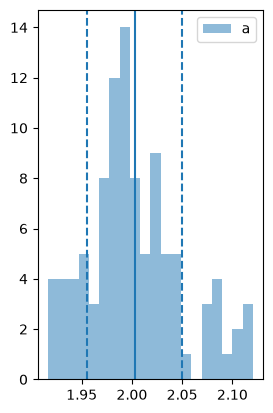

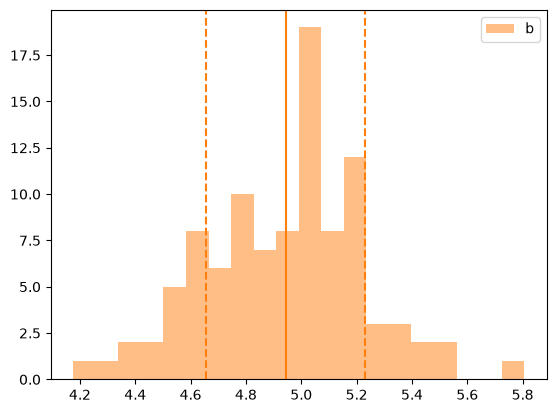

In [8]:
# compute and display corresponding histograms
fig = plt.figure()
ax1 = fig.add_subplot(121)
plt.hist(popt[:,0], bins=20, alpha=0.5, label='a', color='tab:blue')
plt.axvline(a_mean, ls='-', c='tab:blue')
plt.axvline(a_mean-a_std, ls='--', c='tab:blue')
plt.axvline(a_mean+a_std, ls='--', c='tab:blue')
plt.legend()
plt.show()
ax2 = fig.add_subplot(122)
plt.hist(popt[:,1], bins=20, alpha=0.5, label='b', color='tab:orange')
plt.axvline(b_mean, ls='-', c='tab:orange')
plt.axvline(b_mean-b_std, ls='--', c='tab:orange')
plt.axvline(b_mean+b_std, ls='--', c='tab:orange')
plt.legend()
#
plt.show()